In [1]:
#install a foolbox module
!pip install foolbox

     |████████████████████████████████| 1.7 MB 2.1 MB/s 
     |████████████████████████████████| 62 kB 822 kB/s 
     |████████████████████████████████| 180 kB 49.9 MB/s 
     |████████████████████████████████| 63 kB 1.6 MB/s 
  Attempting uninstall: requests
    Found existing installation: requests 2.23.0
    Uninstalling requests-2.23.0:
      Successfully uninstalled requests-2.23.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests~=2.23.0, but you have requests 2.26.0 which is incompatible.
datascience 0.10.6 requires folium==0.2.1, but you have folium 0.8.3 which is incompatible.


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input, decode_predictions
import numpy as np
import matplotlib.pyplot as plt
from foolbox import TensorFlowModel, Model
from foolbox.attacks import LinfFastGradientAttack

In [3]:
model = tf.keras.applications.ResNet50(weights="imagenet")

102981632/102967424 [==============================] - 3s 0us/step


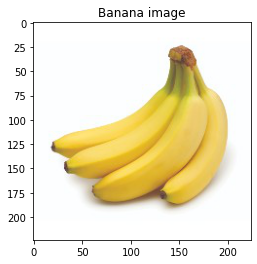

49152/35363 [=========================================] - 0s 0us/step
Predicted: [('n07753592', 'banana', 0.99861276), ('n07753113', 'fig', 0.0004591437), ('n07749582', 'lemon', 0.00022873387)]


In [4]:
img_path = 'banana_origin_224.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

preds = model.predict(x)
plt.figure()
plt.imshow(img)
plt.title('Banana image')
plt.show()
print('Predicted:', decode_predictions(preds, top=3)[0])

In [5]:
pre = dict(flip_axis=-1, mean=[103.939, 116.779, 123.68])  # RGB to BGR
fmodel: Model = TensorFlowModel(model, bounds=(0, 255), preprocessing=pre)

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


In [6]:
# apply the attack
attack = LinfFastGradientAttack()

#так как преобразования к изображению применяются внутри модели foolbox, еще раз поместим его в переменную х
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
banana_image, banana_label = tf.convert_to_tensor(x), tf.convert_to_tensor(tf.cast([954], tf.int64))

#Заданим значения допустимых возмущений
epsilons = [0.0, 0.001, 0.01, 0.03, 0.1, 0.3, 0.5, 1.0, 2.0, 5.0, 10.0]

raw_advs, clipped_advs, success = attack(fmodel, banana_image, banana_label, epsilons=epsilons)


Predicted: [('n07753592', 'banana', 0.44590968), ('n03825788', 'nipple', 0.172575), ('n04522168', 'vase', 0.052172087)]


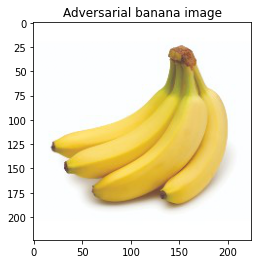

Predicted: [('n07753592', 'banana', 0.44580537), ('n03825788', 'nipple', 0.17252426), ('n04522168', 'vase', 0.05218799)]


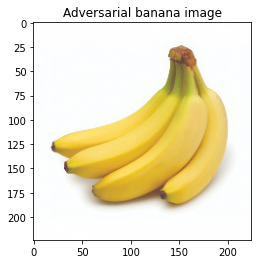

Predicted: [('n07753592', 'banana', 0.44485044), ('n03825788', 'nipple', 0.17207411), ('n04522168', 'vase', 0.05233555)]


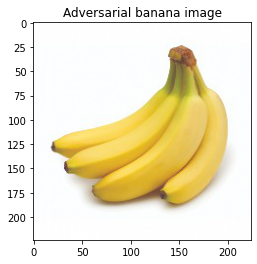

Predicted: [('n07753592', 'banana', 0.4424706), ('n03825788', 'nipple', 0.17113739), ('n04522168', 'vase', 0.05267355)]


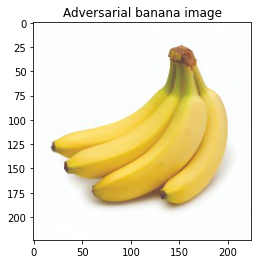

Predicted: [('n07753592', 'banana', 0.43487912), ('n03825788', 'nipple', 0.1660144), ('n04522168', 'vase', 0.05391883)]


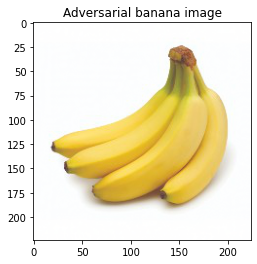

Predicted: [('n07753592', 'banana', 0.42326275), ('n03825788', 'nipple', 0.14756009), ('n04522168', 'vase', 0.05571003)]


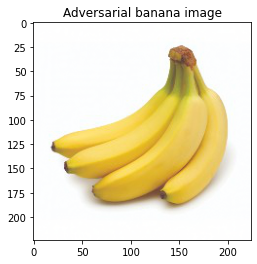

Predicted: [('n07753592', 'banana', 0.40108785), ('n03825788', 'nipple', 0.13709487), ('n04522168', 'vase', 0.05890414)]


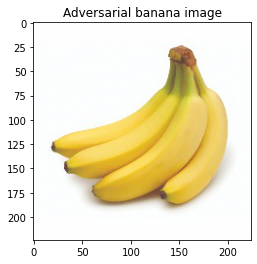

Predicted: [('n07753592', 'banana', 0.35506487), ('n03825788', 'nipple', 0.10025605), ('n04131690', 'saltshaker', 0.073854975)]


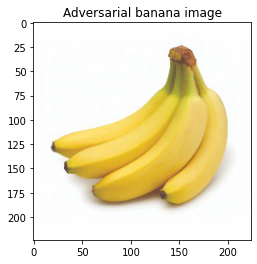

Predicted: [('n07753592', 'banana', 0.28482595), ('n04131690', 'saltshaker', 0.10566427), ('n07753113', 'fig', 0.10099223)]


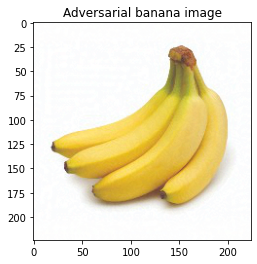

Predicted: [('n07753592', 'banana', 0.113057286), ('n02808304', 'bath_towel', 0.10506969), ('n03775071', 'mitten', 0.079404004)]


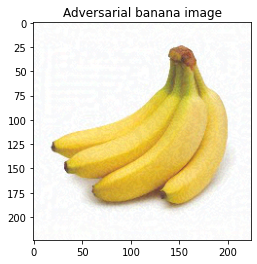

Predicted: [('n03775071', 'mitten', 0.37582743), ('n02808304', 'bath_towel', 0.09073115), ('n03825788', 'nipple', 0.07180546)]


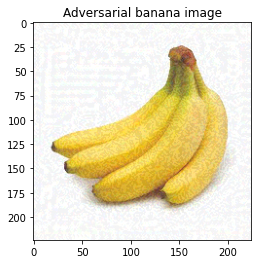

In [7]:
for sample in raw_advs:
  preds = model.predict(sample)
  print('Predicted:', decode_predictions(preds, top=3)[0])
  plt.figure()
  plt.imshow(sample[0]/ 255)
  plt.title('Adversarial banana image')
  plt.show()